In [19]:
import csv

import numpy as np
import matplotlib.pyplot as plt

from vec_gauge import GaugeLattice
from gauge_group import *

Beta: 0.10, Epsilon: 1.00, Acceptance: 0.97
Beta: 0.20, Epsilon: 1.00, Acceptance: 0.93
Beta: 0.30, Epsilon: 1.00, Acceptance: 0.90
Beta: 0.40, Epsilon: 1.00, Acceptance: 0.87
Beta: 0.50, Epsilon: 1.00, Acceptance: 0.84
Beta: 0.60, Epsilon: 1.00, Acceptance: 0.80
Beta: 0.70, Epsilon: 1.00, Acceptance: 0.77
Beta: 0.80, Epsilon: 1.00, Acceptance: 0.74
Beta: 0.90, Epsilon: 1.00, Acceptance: 0.71
Beta: 1.00, Epsilon: 1.00, Acceptance: 0.67
Beta: 1.10, Epsilon: 1.00, Acceptance: 0.64
Beta: 1.20, Epsilon: 1.00, Acceptance: 0.61
Beta: 1.30, Epsilon: 1.00, Acceptance: 0.58
Beta: 1.40, Epsilon: 1.00, Acceptance: 0.55
Beta: 1.50, Epsilon: 0.65, Acceptance: 0.67
Beta: 1.60, Epsilon: 0.65, Acceptance: 0.65
Beta: 1.70, Epsilon: 0.65, Acceptance: 0.63
Beta: 1.80, Epsilon: 0.65, Acceptance: 0.61
Beta: 1.90, Epsilon: 0.65, Acceptance: 0.59
Beta: 2.00, Epsilon: 0.58, Acceptance: 0.61
Beta: 2.10, Epsilon: 0.52, Acceptance: 0.63
Beta: 2.20, Epsilon: 0.52, Acceptance: 0.61
Beta: 2.30, Epsilon: 0.42, Accep

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Beta: 7.90, Epsilon: 0.16, Acceptance: 0.51


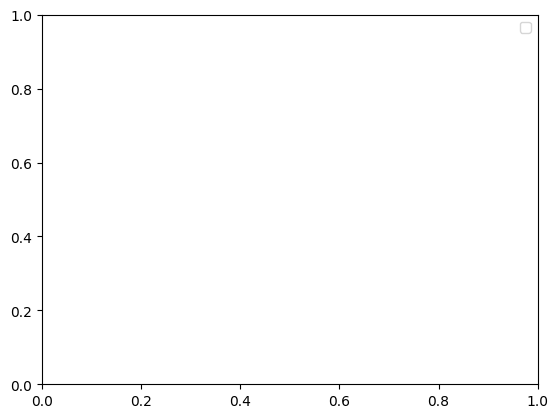

In [20]:
betas = np.arange(0.1, 8, 0.1)
plaquettes = []
M = 8
start = 'cold'
filename = 'plaquette_data.csv'
file = open(filename, 'w+', newline='')

writer = csv.writer(file)

writer.writerow(['beta', 'M', 'start', 'plaquette', 'eps', 'acc_ratio', 'hist1', 'hist'])

for i, beta in enumerate(betas):
    gauge_model = GaugeLattice(grp = SU3(), M = M, beta = beta, start = start, eps = 0.1)
    hist1, _ = gauge_model.sim(50)
    eps, acc = gauge_model.tune_eps(target=0.5, n_sweeps=1, n_iter=20, lo=1e-3, hi=1.0, tol=5e-3)
    hist, acc_ratio = gauge_model.sim(200)
    print(f"Beta: {beta:.2f}, Epsilon: {eps:.2f}, Acceptance: {acc_ratio:.2f}")
    plaquettes.append(np.mean(hist))
    writer.writerow([beta, M, start, np.mean(hist), eps, acc_ratio, _, *hist1, *hist])

file.close()

plt.legend()
plt.show()

plaquettes = np.array(plaquettes)

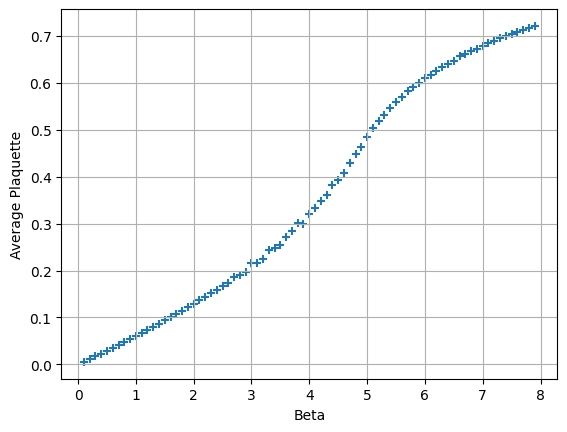

In [21]:
plt.scatter(betas, 1-plaquettes, marker='+')
plt.xlabel('Beta')
plt.ylabel('Average Plaquette')
plt.grid()
plt.show()